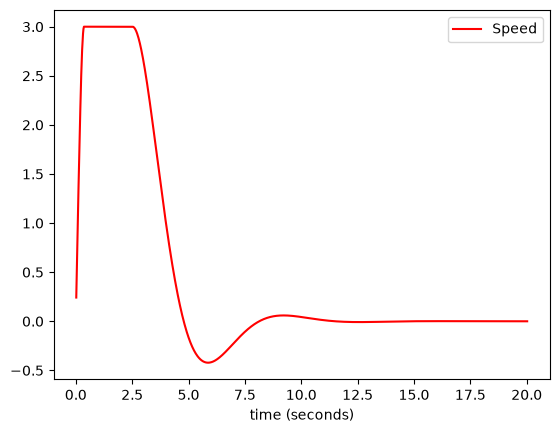

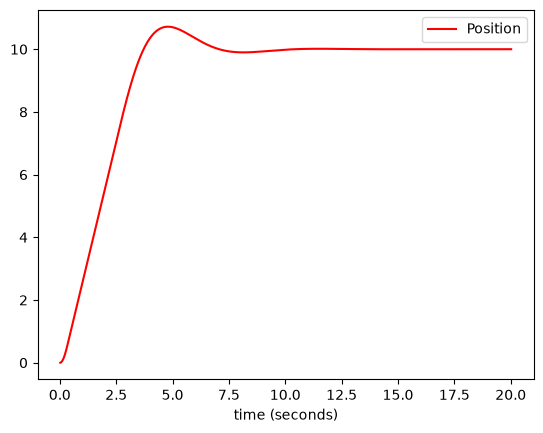

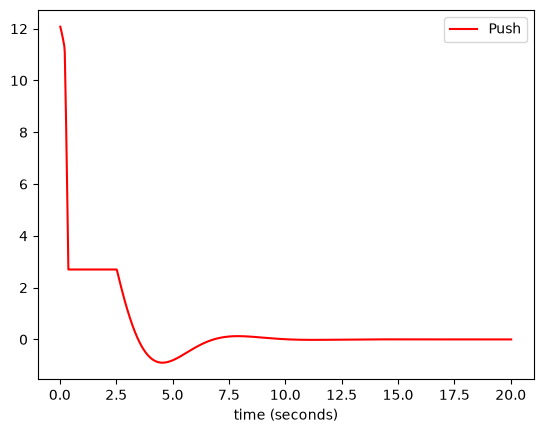

In [2]:
#
# to be tested with godot/cart-1d-no-physics
#

import numpy as np
import arslabrobotics as ar
import scipy.optimize as opt

class MPC_Cart:

    def __init__(self):
        self.model_cart = ar.system.Cart(1.0, 0.9)
        self.Q = np.array([10.0, 0.0])  # Peso alto su errore posizione, basso su velocità
        self.R = 0.5                    # Peso sull'azione di controllo (energia)
        self.max_speed = 3
        self.N = 20
        self.target = np.array([0.0, 0.0])
        self.delta_t = 0.05
        self.initial_state = [0.0, 0.0]
        
        # Vincoli fisici sulla spinta del motore (es. max +-25 Newton)
        self.max_force = 25.0

    def set_target(self, p, v):
        self.target = np.array([ p , v ]).T

    def opt_fun(self, u_array):
        #print(u_array)
        self.model_cart.position = self.initial_state[0]
        self.model_cart.speed = self.initial_state[1]
        total_cost = 0
        for i in range(self.N):
            x = np.array([self.model_cart.position, self.model_cart.speed]).T
            u = u_array[i]
            error = self.target - x
            
            # compute error
            err_p = self.target[0] - self.model_cart.position
            err_v = self.target[1] - self.model_cart.speed
            
            # quadratic cost function: J = x^T*Q*x + u^T*R*u
            cost = (self.Q[0] * (err_p ** 2)) + (self.Q[1] * (err_v ** 2)) + (self.R * (u ** 2))
            total_cost += cost
            
            self.model_cart.evaluate(self.delta_t, u)
        return total_cost

    def optimize(self, delta_t, initial_u, p, v):
        self.initial_state = [p, v]
        self.delta_t = delta_t

        # Initial vector based on last command 
        u_init = np.array([initial_u] * self.N)
        
        # Bounds of the input (saturation)
        bounds = opt.Bounds([-self.max_force] * self.N, [self.max_force] * self.N)

        # constraints
        constraints = [
            {'type': 'ineq', 'fun': self.constraint_speed_max},
        ]
        result = opt.minimize(self.opt_fun, u_init, method='SLSQP', bounds=bounds, constraints=constraints)
        #print(result)
        return result.x

    def _predict_speed_trajectory(self, u_array):
        # determine the trajectory of speed 
        self.model_cart.position = self.initial_state[0]
        self.model_cart.speed = self.initial_state[1]
        
        speeds = []
        
        for i in range(self.N):
            self.model_cart.evaluate(self.delta_t, u_array[i])
            speeds.append(self.model_cart.speed)
            
        return np.array(speeds)
        
    def constraint_speed_max(self, u_array):
        v = self._predict_speed_trajectory(u_array)
        return self.max_speed - v  # output must be  >= 0, so max_speed >= v

    

spd = ar.data.DataPlotter()
spd.set_x("time (seconds)")
spd.add_y("speed", "Speed")

pos = ar.data.DataPlotter()
pos.set_x("time (seconds)")
pos.add_y("pos", "Position")

push = ar.data.DataPlotter()
push.set_x("time (seconds)")
push.add_y("push", "Push")

cart = ar.system.Cart(1.0, 0.9)

ctrl = MPC_Cart()
ctrl.set_target(10,0)

godot_drive = False

if godot_drive:
    dds = ar.dds.DDS()
    dds.start()

#ctrl.optimize(0.1, 100, 0, 0)


t = ar.utils.Time(use_fake_time=not(godot_drive))
t.start()
force = 25
while t.get() < 20:

    t.sleep(0.02)
    delta_t = t.elapsed()

    force_array = ctrl.optimize(delta_t, force, cart.position, cart.speed)
    
    force = force_array[0]
    
    (p, v) = cart.evaluate(delta_t, force)

    if godot_drive:
        dds.publish('position', p, ar.dds.DDS_TYPE_FLOAT)
    
    spd.append_x(t.get())
    spd.append_y("speed", v)
    
    pos.append_x(t.get())
    pos.append_y("pos", p)

    push.append_x(t.get())
    push.append_y("push", force)
    
spd.plot()
pos.plot()
push.plot()
if godot_drive:
    dds.stop()
